In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,UpSampling2D
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv('mnist_train.csv')
test = pd.read_csv('mnist_test.csv')

In [4]:
x_train=train.iloc[:,1:].values
x_test=test.iloc[:,1:].values

In [5]:
x_train = x_train.astype('float32')/255.0
x_test-x_test.astype('float32')/255.0

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [6]:
x_train = np.reshape(x_train,(len(x_train),28,28,1))
x_test = np.reshape(x_test,(len(x_test),28,28,1))

In [7]:
noise_factor = 0.5

In [9]:
x_train_noisy = x_train + noise_factor * np.random.normal(loc=0.0,scale=1.0,size=x_train.shape)
x_test_noisy = x_test + noise_factor * np.random.normal(loc=0.0,scale=1.0,size=x_test.shape)

In [10]:
x_train_noisy = np.clip(x_train_noisy,0.,1.)
x_test_noisy = np.clip(x_test_noisy,0.,1.)

In [12]:
model = Sequential([
    Conv2D(16,(3,3),activation='relu',padding='same',input_shape=(28,28,1)),
    MaxPooling2D((2,2),padding='same'),
    Conv2D(8,(3,3),activation='relu',padding='same'),
    MaxPooling2D((2,2),padding='same'),
    Conv2D(8,(3,3),activation='relu',padding='same'),
    UpSampling2D((2,2)),
    Conv2D(16,(3,3),activation='relu',padding='same'),
    UpSampling2D((2,2)),
    Conv2D(1,(3,3),activation='sigmoid',padding='same')
])

In [13]:
model.compile(optimizer='adam',loss='binary_crossentropy')
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 8)      │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 7, 7, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 28, 28, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 1)      │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,217 (12.57 KB)

 Trainable params: 3,217 (12.57 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model.fit(x_train_noisy,x_train,epochs=5,batch_size=128,shuffle=True,validation_data=(x_test_noisy,x_test))

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 29s 53ms/step - loss: 0.2188 - val_loss: -73.4621
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 25s 53ms/step - loss: 0.1288 - val_loss: -86.8297
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 46ms/step - loss: 0.1203 - val_loss: -98.9887
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 50ms/step - loss: 0.1164 - val_loss: -107.4554
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 23s 50ms/step - loss: 0.1142 - val_loss: -108.8720


In [19]:
denoising_imgs=model.predict(x_test_noisy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


In [20]:
n=10
plt.figure(figsize=(20,6))

<Figure size 2000x600 with 0 Axes>

<Figure size 2000x600 with 0 Axes>

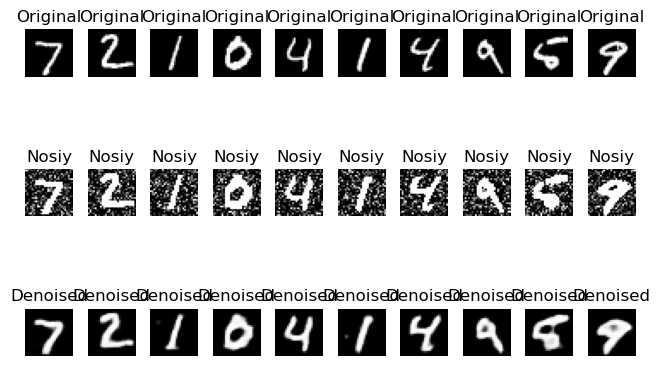

In [24]:
for i in range(n):
    ax=plt.subplot(3,n,i+1)
    plt.imshow(x_test[i].reshape(28,28),cmap='gray')
    plt.title('Original')
    plt.axis('off')

    ax=plt.subplot(3,n,i+1+n)
    plt.imshow(x_test_noisy[i].reshape(28,28),cmap='gray')
    plt.title('Nosiy')
    plt.axis('off')

    ax=plt.subplot(3,n,i+1+2*n)
    plt.imshow(denoising_imgs[i].reshape(28,28),cmap='gray')
    plt.title('Denoised')
    plt.axis('off')
plt.tight_layout()
plt.show()